In [1]:
import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import cv2
from tqdm import tqdm


In [2]:
bucket_size = 6
Age_bucket = 117 // bucket_size + 1 

In [3]:
class AgeDataProcessed(Dataset):
    def __init__(self, root_dir, transform=None,bucket_size=6):
        self.root = root_dir
        self.transform = transform
        self.bucket_size = bucket_size
        self.samples = []

        #as we have differentiated the each age class in different folder
        for age in os.listdir(root_dir):
            age_dir = os.path.join(root_dir, age)
            if not os.path.isdir(age_dir):
                continue

            for img_file in os.listdir(age_dir):
                self.samples.append((os.path.join(age_dir, img_file), int(age)))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, age = self.samples[idx]

        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.transform:
            img = self.transform(img)
            
        bucket = age // self.bucket_size   
        return img, torch.tensor(bucket, dtype=torch.long)


In [4]:
transform = transforms.Compose([
    transforms.ToTensor(), 
    transforms.Resize((224, 224)),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]  #I am using these parameters because ResNet34 was pretrained on these 
    )
])


In [5]:
from sklearn.model_selection import train_test_split

all_samples = "../data/cropped"

dataset = AgeDataProcessed(all_samples, transform=transform,bucket_size=bucket_size)
indices=list(range(len(dataset)))
train_id, test_id = train_test_split(indices, test_size=0.1,random_state=42)
train_id, val_id = train_test_split(train_id, test_size=0.2,random_state=42)


In [6]:
from torch.utils.data import Subset

train_ds = Subset(dataset, train_id)
val_ds = Subset(dataset, val_id)
test_ds = Subset(dataset, test_id)


In [17]:
model = models.resnet34(weights=models.ResNet34_Weights.DEFAULT)

# We freezw the backbone so that the model remebers the training it already has. ImageNet has been trained on a lot more data and thus it ensures a better training on our dataset which is much smaller 
for param in model.layer4.parameters():#Here we are just unfreezing the 4th layer for better tuning to different facial features like wrinkles, maybe beard,hair color etc
    param.requires_grad = True

in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Linear(in_features, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, Age_bucket)  #Since imageNet is trained on images which output a lot more than what we need(Age prediction and not other things) and the model only outputs the bukcet of 6 years age size value that is the age it has predicted and put it in group of 6 years 
)


In [7]:
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)


In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") #I shifted the learning to GPU for faster learning
model.to(device)
device



device(type='cuda')

In [19]:
criterion = nn.CrossEntropyLoss()# Mean absolute error was used earlier but due to a variation of 5 years, we decided to bucket to 6 years so the accuracy is better and the model works better
trainable_params=[p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(trainable_params, lr=0.00001) #We use Adam optimizer


In [20]:
epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0
    
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        
        out = model(x).squeeze()
        loss = criterion(out, y)
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    # validation set
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x).squeeze()
            val_loss += criterion(out, y).item()

    print(f"Epoch {epoch+1}/{epochs} / Train Error: {total_loss/len(train_loader):.3f} / Validation Error: {val_loss/len(val_loader):.3f}")


Epoch 1/5 / Train Error: 2.233 / Validation Error: 1.739
Epoch 2/5 / Train Error: 1.682 / Validation Error: 1.519
Epoch 3/5 / Train Error: 1.478 / Validation Error: 1.437
Epoch 4/5 / Train Error: 1.310 / Validation Error: 1.421
Epoch 5/5 / Train Error: 1.142 / Validation Error: 1.464


In [21]:
torch.save(model.state_dict(), "../models/Training_Data_Bucket_Save.pth")

In [22]:
model = models.resnet34(weights=None)

in_features = model.fc.in_features
model.fc = nn.Sequential(
    nn.Linear(in_features, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, Age_bucket)
)

model.load_state_dict(torch.load("../models/Training_Data_Bucket_Save.pth", map_location=device))
model = model.to(device)
model.eval()

criterion = nn.CrossEntropyLoss()

ipykernel_16500\2234338003.py:11: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("Training_Data_Bucket_Save.pth", map_location=device))


In [23]:
correct = 0
total = 0
test_loss = 0

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)

        outputs = model(imgs)
        loss = criterion(outputs, labels)
        test_loss += loss.item()

        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

test_loss /= len(test_loader)
test_acc = correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")


Test Loss: 1.4912
Test Accuracy: 0.4485


In [24]:
print(model.fc)

Sequential(
  (0): Linear(in_features=512, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=128, out_features=20, bias=True)
)


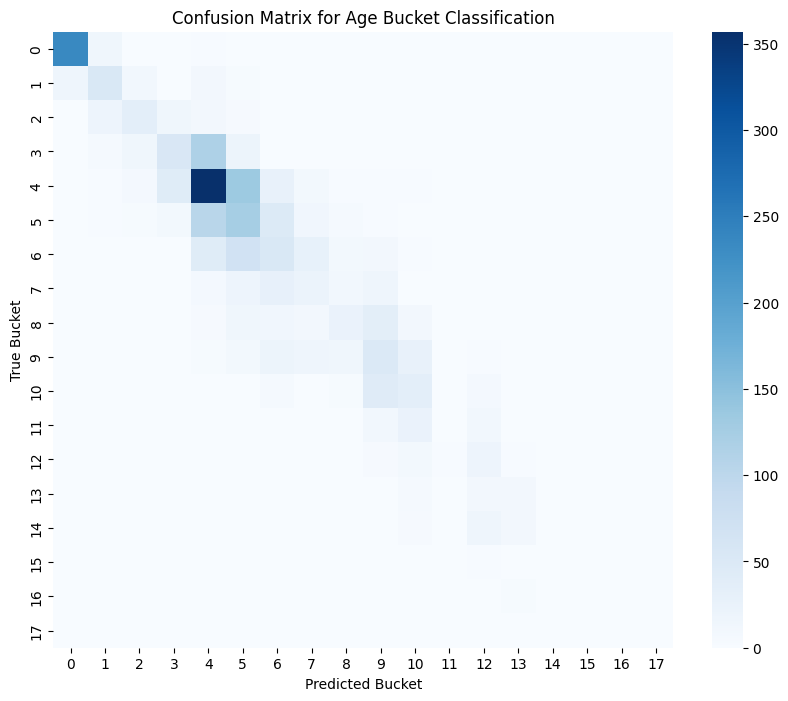

In [31]:
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

#We plot the confusion matrix to get a deeper understanding of the prediction and where the model fails or lacks
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues')
plt.title("Confusion Matrix for Age Bucket Classification")
plt.xlabel("Predicted Bucket")
plt.ylabel("True Bucket")
plt.show()


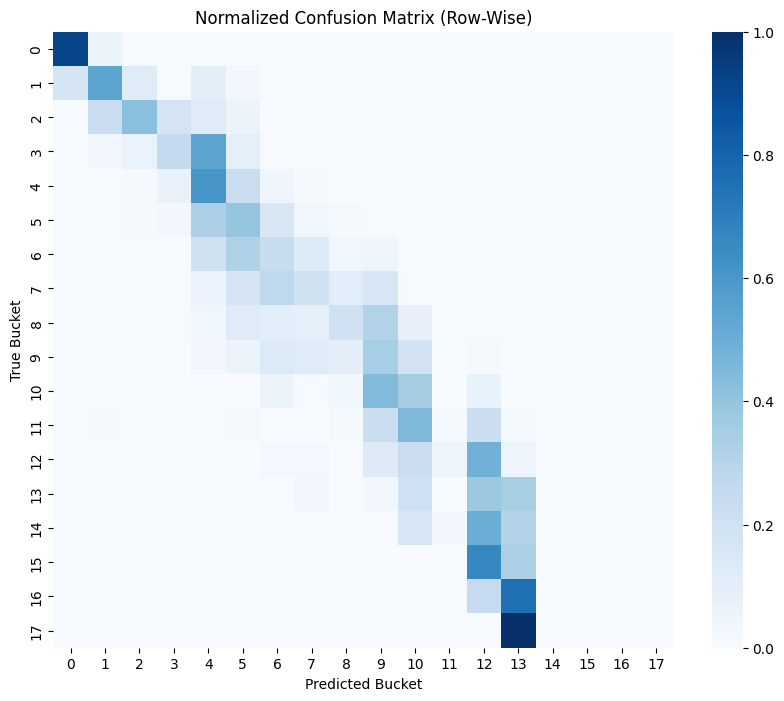

In [32]:
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_norm, annot=False, cmap='Blues')
plt.title("Normalized Confusion Matrix (Row-Wise)")
plt.xlabel("Predicted Bucket")
plt.ylabel("True Bucket")
plt.show()

